# 10 Research question audit

Uses the active Notebook 09 models. No model training or test-set analysis. Validation importance is descriptive evidence from the selection period, not a new independent performance estimate. Budget analysis uses training-period films with known budgets and positive revenue. Franchise, sequel gaps and sentiment remain deferred. Run every cell in order.

## 01 Load and validate evidence

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import sklearn
import joblib
from sklearn.metrics import mean_squared_error, roc_auc_score
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Data/Models/Final/model_manifest.json").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook within the project folder.")
MODEL_DIR = PROJECT_ROOT / "Data/Models/Final"
manifest = json.loads((MODEL_DIR / "model_manifest.json").read_text())
if sklearn.__version__ != manifest["scikit_learn_version"]:
    raise RuntimeError(f"Use the original model environment: scikit-learn {manifest['scikit_learn_version']}; found {sklearn.__version__}. Do not retrain to bypass this check.")
# Load only the trusted model artifacts from this project.
regressor = joblib.load(MODEL_DIR / manifest["regression_model"])
classifier = joblib.load(MODEL_DIR / manifest["classification_model"])
X = pd.read_csv(PROJECT_ROOT / "Data/Model_Ready/Features/X_validation.csv")
y_reg = pd.read_csv(PROJECT_ROOT / "Data/Model_Ready/Targets/y_validation_regression.csv")["log_worldwide_box_office"].to_numpy()
y_cls = pd.read_csv(PROJECT_ROOT / "Data/Model_Ready/Targets/y_validation_classification.csv")["blockbuster"].to_numpy()
reference = pd.read_csv(PROJECT_ROOT / "Data/Model_Ready/Metadata/historical_split_reference.csv")
vref = reference.loc[reference['split'].eq('validation')].reset_index(drop=True)
if not len(X) == len(y_reg) == len(y_cls) == len(vref):
    raise ValueError("Validation row counts differ.")
if not np.allclose(y_reg, np.log1p(vref.worldwide_box_office)):
    raise ValueError("Validation outcomes are misaligned.")
if list(X.columns) != manifest['processed_feature_columns']:
    raise ValueError("Feature order differs from the active manifest.")
for model in [regressor, classifier]:
    if list(model.feature_names_in_) != list(X.columns):
        raise ValueError("Saved model schema differs.")
if not np.isfinite(X.to_numpy()).all():
    raise ValueError("Validation features contain invalid values.")
positive_index = list(classifier.classes_).index(1)
meta = json.loads((PROJECT_ROOT / 'Data/Model_Ready/Metadata/model_ready_metadata.json').read_text())
if not np.array_equal(y_cls, (vref.worldwide_box_office >= meta['blockbuster_threshold_usd']).astype(int)):
    raise ValueError('Validation class labels disagree with the training cutoff.')
OUT = PROJECT_ROOT / "Data/Results/Research_Question_Audit"
FIG = PROJECT_ROOT / "Reports/Figures/Research_Question_Audit"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
print(f"Loaded {len(X)} validation rows. No test data loaded.")


Loaded 600 validation rows. No test data loaded.


## 02 Establish validation reference scores

In [2]:
base_rmse = np.sqrt(mean_squared_error(y_reg, regressor.predict(X)))
base_auc = roc_auc_score(y_cls, classifier.predict_proba(X)[:, positive_index])
print(f"Validation log RMSE: {base_rmse:.6f}; ROC-AUC: {base_auc:.6f}")
if not (np.isclose(base_rmse, 1.414490, atol=1e-5) and np.isclose(base_auc, 0.915272, atol=1e-5)):
    raise ValueError("Reference scores differ from the audited active models. Investigate before interpreting importance.")


c:\Users\bongo\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\bongo\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\bongo\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\bongo\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

Validation log RMSE: 1.414490; ROC-AUC: 0.915272


## 03 Grouped permutation importance

Shuffle related columns together to preserve valid one-hot categories and relationships within each group. An increase in log RMSE or a decrease in ROC-AUC indicates useful predictive information. Correlated groups can substitute for one another; this does not identify causal effects. Error bars show variability across permutations, not confidence intervals.

In [3]:
groups = {
    "Budget and missingness": ["log_budget", "budget_missing"],
    "Release timing": ["release_year", "release_month", "holiday_release"] + [c for c in X if c.startswith("release_season_")],
    "Director history": [c for c in X if c.startswith("director_")],
    "Lead star history": [c for c in X if c.startswith("star_")],
    "Company history": [c for c in X if c.startswith("company_")],
    "Genre": [c for c in X if c.startswith("primary_genre_")],
}
covered = [c for columns in groups.values() for c in columns]
if len(covered) != len(set(covered)) or set(covered) != set(X):
    raise ValueError("Feature groups overlap or omit columns.")
rows = []
for repeat in range(10):
    order = np.random.default_rng(42 + repeat).permutation(len(X))
    for group, columns in groups.items():
        shuffled = X.copy()
        shuffled.loc[:, columns] = X.iloc[order][columns].to_numpy()
        rmse = np.sqrt(mean_squared_error(y_reg, regressor.predict(shuffled)))
        auc = roc_auc_score(y_cls, classifier.predict_proba(shuffled)[:, positive_index])
        rows.append(dict(group=group, repeat=repeat + 1, log_rmse_increase=rmse-base_rmse, roc_auc_decrease=base_auc-auc))
    print(f"Permutation repeat {repeat+1}/10 complete")
importance_runs = pd.DataFrame(rows)
importance = importance_runs.groupby('group', sort=False).agg(
    log_rmse_increase=('log_rmse_increase','mean'), rmse_repeat_sd=('log_rmse_increase','std'),
    roc_auc_decrease=('roc_auc_decrease','mean'), auc_repeat_sd=('roc_auc_decrease','std')
).reset_index()
importance_runs.to_csv(OUT / 'grouped_importance_repeats.csv', index=False)
importance.to_csv(OUT / 'grouped_importance_summary.csv', index=False)
display(importance.sort_values('log_rmse_increase', ascending=False))


Permutation repeat 1/10 complete
Permutation repeat 2/10 complete
Permutation repeat 3/10 complete
Permutation repeat 4/10 complete
Permutation repeat 5/10 complete
Permutation repeat 6/10 complete
Permutation repeat 7/10 complete
Permutation repeat 8/10 complete
Permutation repeat 9/10 complete
Permutation repeat 10/10 complete


,group,log_rmse_increase,rmse_repeat_sd,roc_auc_decrease,auc_repeat_sd
0,Budget and missingness,0.993105,0.044784,0.193877,0.021132
4,Company history,0.230193,0.031059,0.016498,0.007564
2,Director history,0.080826,0.018914,0.001847,0.004689
3,Lead star history,0.032567,0.011026,0.003851,0.002143
5,Genre,0.031948,0.009987,0.005356,0.002738
1,Release timing,0.025073,0.011352,0.009659,0.004101


## 04 Plot validation importance

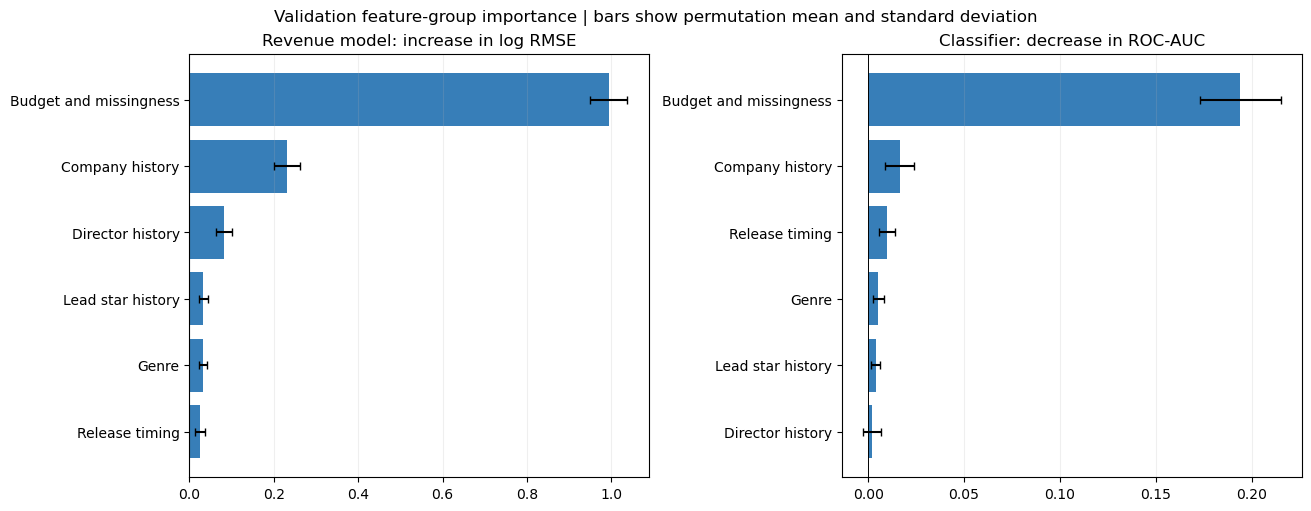

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, metric, spread, title in zip(axes, ['log_rmse_increase','roc_auc_decrease'], ['rmse_repeat_sd','auc_repeat_sd'], ['Revenue model: increase in log RMSE','Classifier: decrease in ROC-AUC']):
    plot = importance.sort_values(metric)
    ax.barh(plot.group, plot[metric], xerr=plot[spread], color='#377EB8', capsize=3)
    ax.axvline(0, color='black', linewidth=.7)
    ax.set_title(title)
    ax.grid(axis='x', alpha=.2)
fig.suptitle('Validation feature-group importance | bars show permutation mean and standard deviation')
fig.savefig(FIG / '01_validation_grouped_importance.png', dpi=250, bbox_inches='tight')
plt.show()
plt.close(fig)


## 05 Historical budget evidence

This analysis concerns observed revenue relative to production budget. It does not measure studio profit or establish what additional spending causes. It excludes missing budgets and uses nominal dollars, so selection, inflation and genre/year differences remain limitations.

In [5]:
historical = pd.read_csv(PROJECT_ROOT / 'Data/Features/historical_model_features.csv')
budget_data = historical.loc[historical.release_year.le(meta['training_end_year']) & historical.log_budget.notna() & historical.worldwide_box_office.gt(0)].copy()
budget_data['budget_usd'] = np.expm1(budget_data.log_budget)
budget_data = budget_data.loc[budget_data.budget_usd.gt(0)].copy()
budget_data['gross_per_budget_dollar'] = budget_data.worldwide_box_office / budget_data.budget_usd
edges = [0, 10e6, 25e6, 50e6, 100e6, 200e6, np.inf]
labels = ['Under $10m', '$10m to $25m', '$25m to $50m', '$50m to $100m', '$100m to $200m', '$200m or more']
budget_data['budget_band'] = pd.cut(budget_data.budget_usd, bins=edges, labels=labels, right=False)
bands = budget_data.groupby('budget_band', observed=True).agg(
    movies=('title','size'), median_budget_usd=('budget_usd','median'),
    median_revenue_usd=('worldwide_box_office','median'),
    median_gross_per_budget_dollar=('gross_per_budget_dollar','median')
).reset_index()
bands.to_csv(OUT / 'historical_budget_bands.csv', index=False)
display(bands)
print(f'Training-period films with usable budget and revenue: {len(budget_data):,}')


,budget_band,movies,median_budget_usd,median_revenue_usd,median_gross_per_budget_dollar
0,Under $10m,1321,5000000.0,7390108.0,1.820270
1,$10m to $25m,1538,17500000.0,24520819.5,1.412408
2,$25m to $50m,961,35000000.0,57319029.0,1.644492
3,$50m to $100m,776,65948884.0,129358260.5,1.931348
4,$100m to $200m,236,135000000.0,371402319.0,2.748875
5,$200m or more,47,210000000.0,746045700.0,3.468928


Training-period films with usable budget and revenue: 4,879


## 06 Descriptive proportional-return check

Fit a simple log–log association separately below and above the training sample’s median budget. A slope below 1 means subproportional revenue growth within that sample; a lower high-budget slope is consistent with diminishing proportional returns. Neither result establishes causation or dollar marginal returns. Bootstrap intervals resample films and do not address confounding or time dependence. This auxiliary statistical fit does not replace or retrain the saved prediction models.

In [6]:
median_budget = budget_data.budget_usd.median()
slope_rows = []
for label, subset in [('Lower budget', budget_data[budget_data.budget_usd <= median_budget]), ('Higher budget', budget_data[budget_data.budget_usd > median_budget])]:
    x = np.log(subset.budget_usd.to_numpy())
    y = np.log(subset.worldwide_box_office.to_numpy())
    def slope(a, b):
        return float(np.linalg.lstsq(np.column_stack([np.ones(len(a)), a]), b, rcond=None)[0][1])
    estimate = slope(x,y)
    rng = np.random.default_rng(42)
    samples = []
    for _ in range(500):
        index = rng.integers(0,len(x),len(x))
        samples.append(slope(x[index],y[index]))
    lo, hi = np.quantile(samples,[.025,.975])
    slope_rows.append(dict(budget_group=label,movies=len(x),split_budget_usd=median_budget,log_log_slope=estimate,bootstrap_low=lo,bootstrap_high=hi))
slopes = pd.DataFrame(slope_rows)
slopes.to_csv(OUT / 'budget_proportional_return_slopes.csv',index=False)
display(slopes)
print('Read the slopes with the budget-band table. Do not interpret them as causal returns to spending.')


,budget_group,movies,split_budget_usd,log_log_slope,bootstrap_low,bootstrap_high
0,Lower budget,2477,20000000.0,0.638442,0.565478,0.709059
1,Higher budget,2402,20000000.0,1.370357,1.302216,1.438676


Read the slopes with the budget-band table. Do not interpret them as causal returns to spending.


## 07 Plot budget associations and save interpretation notes

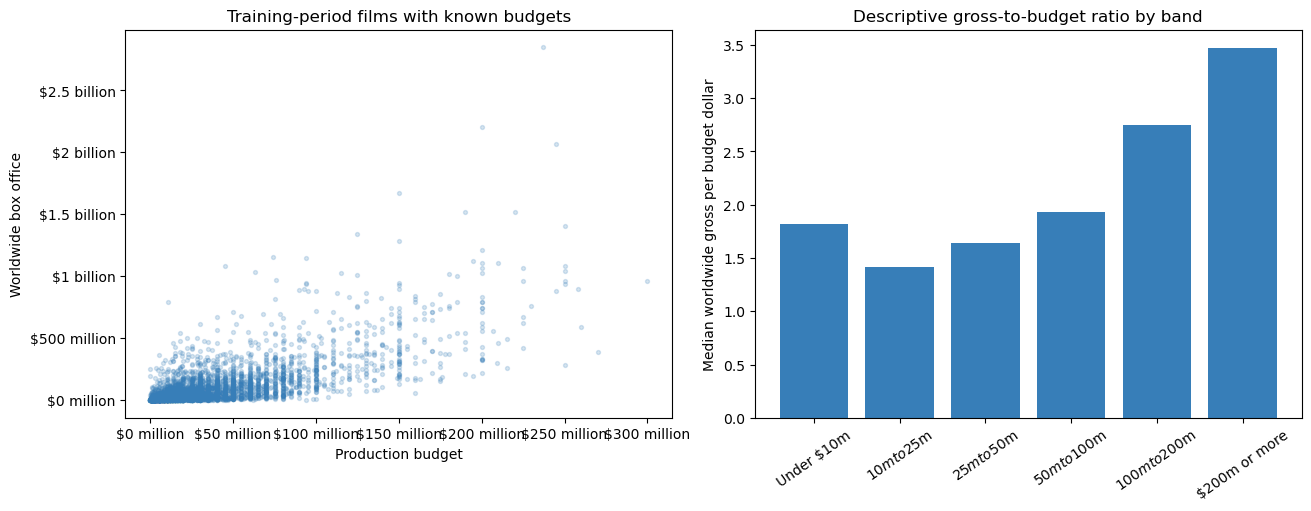

Saved results: c:\Users\bongo\OneDrive\Desktop\GitHub\Movie Analysis Predictor\Data\Results\Research_Question_Audit
Saved figures: c:\Users\bongo\OneDrive\Desktop\GitHub\Movie Analysis Predictor\Reports\Figures\Research_Question_Audit
Return grouped_importance_summary.csv, historical_budget_bands.csv and budget_proportional_return_slopes.csv for interpretation.


In [7]:
def money(value, position=None):
    return f'${value/1e9:g} billion' if abs(value)>=1e9 else f'${value/1e6:g} million'
fig, axes = plt.subplots(1, 2, figsize=(13,5), constrained_layout=True)
axes[0].scatter(budget_data.budget_usd, budget_data.worldwide_box_office, s=8, alpha=.2, color='#377EB8')
axes[0].xaxis.set_major_formatter(FuncFormatter(money))
axes[0].yaxis.set_major_formatter(FuncFormatter(money))
axes[0].set(xlabel='Production budget', ylabel='Worldwide box office', title='Training-period films with known budgets')
axes[1].bar(bands.budget_band.astype(str),bands.median_gross_per_budget_dollar,color='#377EB8')
axes[1].tick_params(axis='x',rotation=35)
axes[1].set(ylabel='Median worldwide gross per budget dollar',title='Descriptive gross-to-budget ratio by band')
fig.savefig(FIG / '02_historical_budget_returns.png',dpi=250,bbox_inches='tight')
plt.show()
plt.close(fig)
notes = {
    'model_family': 'Notebook 09 train-only models in Data/Models/Final',
    'validation_rows': len(X), 'reference_log_rmse': float(base_rmse), 'reference_roc_auc': float(base_auc),
    'permutation_repeats':10, 'budget_sample_rows':len(budget_data), 'budget_bootstrap_repeats':500,
    'test_data_used':False,
    'model_sha256':{name:hashlib.sha256((MODEL_DIR / manifest[name]).read_bytes()).hexdigest() for name in ['regression_model','classification_model']},
    'limitations':[
        'Validation was previously used for model selection; importance is descriptive.',
        'Correlated feature groups can substitute for one another.',
        'Permutation standard deviations are not confidence intervals.',
        'Budget slopes are unadjusted observational associations in nominal dollars.',
        'Budget bands have unequal sample sizes; inspect counts.',
        'Gross divided by budget is not studio profit or ROI.',
        'Bootstrap intervals do not address confounding, selection or dependence.',
        'Franchise, sequel gaps and sentiment remain deferred.'
    ]
}
(OUT / 'research_audit_notes.json').write_text(json.dumps(notes,indent=2))
print('Saved results:', OUT)
print('Saved figures:', FIG)
print('Return grouped_importance_summary.csv, historical_budget_bands.csv and budget_proportional_return_slopes.csv for interpretation.')
